# PR-5: Smart Outcome Predictor

**Objective:**
The objective of this project is to design a robust ensemble-based machine learning system capable of predicting outcomes accurately by combining multiple weak and strong learners. We explore bagging, boosting, voting, and stacking strategies for both classification and regression tasks.

**Problem Statement:**
Working as a Machine Learning Engineer at an EdTech analytics company:
- **Classification Task:** Predict whether a student will *successfully complete* an online course (`completion_status`: 0 = Not Completed, 1 = Completed).
- **Regression Task:** Predict the *final performance score* of a student (`final_score`: 0–100).


## Part-A: Conceptual Foundation (Theory)

1. What are Ensemble Learning Methods and why are they effective?
- Ensemble learning methods combine multiple individual machine learning models (base learners) to produce a single stronger predictive model.
- They are effective because combining diverse models reduces the risk of errors from any single model, lowers variance or bias, and significantly improves generalization on unseen data.

2. Explain the difference between Bagging, Boosting, and Voting.
- **Bagging (Bootstrap Aggregating):** Trains multiple base models in parallel on random subsets of data (with replacement) and averages their predictions to reduce variance (e.g., Random Forest).
- **Boosting:** Trains models sequentially, where each new model focuses on correcting the errors made by previous models, primarily reducing bias (e.g., AdaBoost, Gradient Boosting).
- **Voting:** Combines predictions from different types of pre-trained models using majority voting (classification) or simple averaging (regression).

3. What is Bias-Variance Trade-off, and how do ensemble methods address it?
- The bias-variance trade-off represents the balance between underfitting (high bias, overly simple model) and overfitting (high variance, overly complex model).
- Ensemble methods address this trade-off directly: Bagging reduces variance without increasing bias by averaging independent trees, while Boosting reduces bias by iteratively fitting residuals.

4. Explain Voting Classifier and Stacking Ensemble.
- **Voting Classifier:** Combines predictions of multiple distinct classifiers using Hard Voting (majority class label) or Soft Voting (averaging predicted class probabilities).
- **Stacking Ensemble:** Trains multiple diverse base models, and instead of simple voting, uses their predictions as inputs to train a higher-level meta-model (e.g., Logistic Regression or Linear Regression).

5. Compare AdaBoost, Gradient Boosting, LightGBM, and XGBoost conceptually.
- **AdaBoost:** Adjusts sample weights at each step, giving higher weight to incorrectly predicted instances.
- **Gradient Boosting:** Fits subsequent trees to the negative gradient (pseudo-residuals) of the loss function using gradient descent.
- **LightGBM:** Uses histogram-based splitting and leaf-wise (best-first) tree growth, making it extremely fast on large datasets with low memory usage.
- **XGBoost:** Enhances gradient boosting with exact second-order Taylor expansion gradients (Hessians), L1/L2 tree regularization, and shrinkage.


## Part-B: Dataset Understanding & Preparation


In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer

# Load dataset
df = pd.read_csv("PR-5.csv")
print("Dataset Shape:", df.shape)
print(df.head())


Dataset Shape: (5200, 19)
   student_id  age  ... completion_status final_score
0      700001   32  ...                 0        49.8
1      700002   17  ...                 1        84.0
2      700003   25  ...                 0        62.5
3      700004   26  ...                 1        89.5
4      700005   26  ...                 0        67.4

[5 rows x 19 columns]


### 6. Identify features and target variables for both tasks.


In [2]:
# Classification target
target_classification = "completion_status"

# Regression target
target_regression = "final_score"

# Drop ID and date columns as they are not predictive features
drop_cols = ["student_id", "course_start_date", target_classification, target_regression]
input_features = df.drop(columns=drop_cols).columns

print("Input Features:", list(input_features))
print("\nClassification Target Variable:", target_classification)
print("Regression Target Variable:", target_regression)


Input Features: ['age', 'country_region', 'device_type', 'education_background', 'course_level', 'course_category', 'week_of_year', 'sessions', 'time_spent_hours', 'videos_watched', 'quiz_attempts', 'assignments_submitted', 'forum_posts', 'avg_quiz_score', 'attendance_rate']

Classification Target Variable: completion_status
Regression Target Variable: final_score


### 7. Perform a train-test split for classification and regression problems.


In [3]:
# Separate features and target variables
X = df[input_features].copy()
y_class = df[target_classification].copy()
y_reg = df[target_regression].copy()

# Encode categorical text columns using LabelEncoder
categorical_cols = X.select_dtypes(include=["object"]).columns
le = LabelEncoder()
for col in categorical_cols:
    X[col] = le.fit_transform(X[col])

# Impute missing values with median
imputer = SimpleImputer(strategy="median")
X = pd.DataFrame(imputer.fit_transform(X), columns=input_features)

# Train-Test Split for Classification (80% train / 20% test)
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X, y_class, test_size=0.2, random_state=42, stratify=y_class
)

# Train-Test Split for Regression (80% train / 20% test)
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X, y_reg, test_size=0.2, random_state=42
)

print("Classification - Train:", X_train_c.shape, "Test:", X_test_c.shape)
print("Regression     - Train:", X_train_r.shape, "Test:", X_test_r.shape)


Classification - Train: (4160, 15) Test: (1040, 15)
Regression     - Train: (4160, 15) Test: (1040, 15)


### 8. Apply basic preprocessing (scaling/encoding if required).


In [4]:
# Standardize features using StandardScaler
scaler_c = StandardScaler()
X_train_c = scaler_c.fit_transform(X_train_c)
X_test_c = scaler_c.transform(X_test_c)

scaler_r = StandardScaler()
X_train_r = scaler_r.fit_transform(X_train_r)
X_test_r = scaler_r.transform(X_test_r)

print("Preprocessing complete!")
print("Sample scaled feature values:", np.round(X_train_c[0][:5], 3))


Preprocessing complete!
Sample scaled feature values: [-0.423  1.131  0.431  0.392 -0.321]


## Part-C: Bagging (Bootstrap Aggregating)

### 9. Implement Bagging Classifier for course completion prediction.


In [5]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score

# Train Bagging Classifier
bag_clf = BaggingClassifier(
    estimator=DecisionTreeClassifier(),
    n_estimators=50,
    random_state=42
)
bag_clf.fit(X_train_c, y_train_c)

y_pred_bag_c = bag_clf.predict(X_test_c)

print("Bagging Classifier Accuracy:", round(accuracy_score(y_test_c, y_pred_bag_c) * 100, 2), "%")
print("Bagging Classifier F1-Score:", round(f1_score(y_test_c, y_pred_bag_c), 4))


Bagging Classifier Accuracy: 70.48 %
Bagging Classifier F1-Score: 0.5823


### 10. Implement Bagging Regressor for final score prediction.


In [6]:
from sklearn.ensemble import BaggingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# Train Bagging Regressor
bag_reg = BaggingRegressor(
    estimator=DecisionTreeRegressor(),
    n_estimators=50,
    random_state=42
)
bag_reg.fit(X_train_r, y_train_r)

y_pred_bag_r = bag_reg.predict(X_test_r)

print("Bagging Regressor MAE:     ", round(mean_absolute_error(y_test_r, y_pred_bag_r), 4))
print("Bagging Regressor R2-Score:", round(r2_score(y_test_r, y_pred_bag_r), 4))


Bagging Regressor MAE:      8.108
Bagging Regressor R2-Score: 0.4508


### 11. Compare bagging results with a single base model.


In [7]:
# Single Base Models (Decision Tree)
dt_clf = DecisionTreeClassifier(random_state=42)
dt_clf.fit(X_train_c, y_train_c)
y_pred_dt_c = dt_clf.predict(X_test_c)

dt_reg = DecisionTreeRegressor(random_state=42)
dt_reg.fit(X_train_r, y_train_r)
y_pred_dt_r = dt_reg.predict(X_test_r)

# Comparison table
comparison_bagging = pd.DataFrame({
    "Task": ["Classification (Accuracy %)", "Regression (R2 Score)"],
    "Single Base Model (Decision Tree)": [
        round(accuracy_score(y_test_c, y_pred_dt_c) * 100, 2),
        round(r2_score(y_test_r, y_pred_dt_r), 4)
    ],
    "Bagging Ensemble": [
        round(accuracy_score(y_test_c, y_pred_bag_c) * 100, 2),
        round(r2_score(y_test_r, y_pred_bag_r), 4)
    ]
})
print(comparison_bagging.to_string(index=False))


                       Task  Single Base Model (Decision Tree)  Bagging Ensemble
Classification (Accuracy %)                            62.4000           70.4800
      Regression (R2 Score)                            -0.0223            0.4508


## Part-D: Boosting Algorithms

## - AdaBoost

### 12. Implement AdaBoost Classifier.


In [8]:
from sklearn.ensemble import AdaBoostClassifier

ada_clf = AdaBoostClassifier(n_estimators=50, random_state=42)
ada_clf.fit(X_train_c, y_train_c)

y_pred_ada_c = ada_clf.predict(X_test_c)

print("AdaBoost Classifier Accuracy:", round(accuracy_score(y_test_c, y_pred_ada_c) * 100, 2), "%")
print("AdaBoost Classifier F1-Score:", round(f1_score(y_test_c, y_pred_ada_c), 4))


AdaBoost Classifier Accuracy: 73.37 %
AdaBoost Classifier F1-Score: 0.6169


### 13. Implement AdaBoost Regressor.


In [9]:
from sklearn.ensemble import AdaBoostRegressor

ada_reg = AdaBoostRegressor(n_estimators=50, random_state=42)
ada_reg.fit(X_train_r, y_train_r)

y_pred_ada_r = ada_reg.predict(X_test_r)

print("AdaBoost Regressor MAE:     ", round(mean_absolute_error(y_test_r, y_pred_ada_r), 4))
print("AdaBoost Regressor R2-Score:", round(r2_score(y_test_r, y_pred_ada_r), 4))


AdaBoost Regressor MAE:      8.5451
AdaBoost Regressor R2-Score: 0.4114


### 14. Analyze how weak learners improve sequentially.


Initial Estimator Accuracy: 66.25 %
Final Ensembled Accuracy:   73.37 %


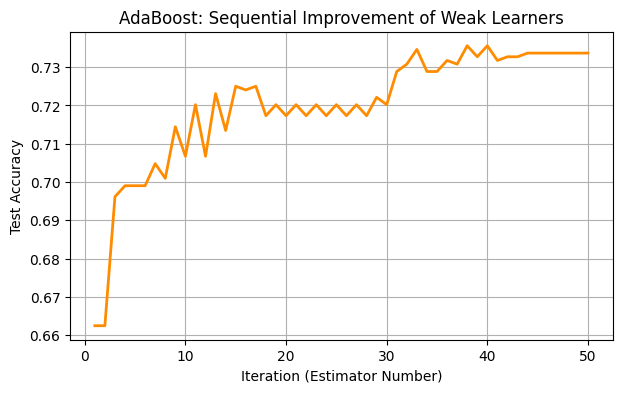

In [10]:
# Track staged score progression across iterations
staged_acc = [accuracy_score(y_test_c, pred) for pred in ada_clf.staged_predict(X_test_c)]

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(staged_acc) + 1), staged_acc, color="darkorange", linewidth=2)
plt.title("AdaBoost: Sequential Improvement of Weak Learners")
plt.xlabel("Iteration (Estimator Number)")
plt.ylabel("Test Accuracy")
plt.grid(True)
plt.show()

print("Initial Estimator Accuracy:", round(staged_acc[0] * 100, 2), "%")
print("Final Ensembled Accuracy:  ", round(staged_acc[-1] * 100, 2), "%")


## - Gradient Boosting

### 15. Implement Gradient Boosting Classifier.


In [11]:
from sklearn.ensemble import GradientBoostingClassifier

gb_clf = GradientBoostingClassifier(n_estimators=50, learning_rate=0.1, random_state=42)
gb_clf.fit(X_train_c, y_train_c)

y_pred_gb_c = gb_clf.predict(X_test_c)

print("Gradient Boosting Classifier Accuracy:", round(accuracy_score(y_test_c, y_pred_gb_c) * 100, 2), "%")
print("Gradient Boosting Classifier F1-Score:", round(f1_score(y_test_c, y_pred_gb_c), 4))


Gradient Boosting Classifier Accuracy: 73.85 %
Gradient Boosting Classifier F1-Score: 0.619


### 16. Implement Gradient Boosting Regressor.


In [12]:
from sklearn.ensemble import GradientBoostingRegressor

gb_reg = GradientBoostingRegressor(n_estimators=50, learning_rate=0.1, random_state=42)
gb_reg.fit(X_train_r, y_train_r)

y_pred_gb_r = gb_reg.predict(X_test_r)

print("Gradient Boosting Regressor MAE:     ", round(mean_absolute_error(y_test_r, y_pred_gb_r), 4))
print("Gradient Boosting Regressor R2-Score:", round(r2_score(y_test_r, y_pred_gb_r), 4))


Gradient Boosting Regressor MAE:      7.9158
Gradient Boosting Regressor R2-Score: 0.4776


### 17. Analyze learning rate and number of estimators.


In [13]:
# Experiment with learning rate and number of estimators
for lr in [0.01, 0.1, 0.2]:
    for n_est in [30, 50, 100]:
        m = GradientBoostingClassifier(n_estimators=n_est, learning_rate=lr, random_state=42)
        m.fit(X_train_c, y_train_c)
        acc = accuracy_score(y_test_c, m.predict(X_test_c))
        print("Learning Rate:", lr, "| Estimators:", n_est, "-> Accuracy:", round(acc * 100, 2), "%")


Learning Rate: 0.01 | Estimators: 30 -> Accuracy: 62.5 %
Learning Rate: 0.01 | Estimators: 50 -> Accuracy: 66.92 %
Learning Rate: 0.01 | Estimators: 100 -> Accuracy: 69.9 %
Learning Rate: 0.1 | Estimators: 30 -> Accuracy: 74.04 %
Learning Rate: 0.1 | Estimators: 50 -> Accuracy: 73.85 %
Learning Rate: 0.1 | Estimators: 100 -> Accuracy: 73.75 %
Learning Rate: 0.2 | Estimators: 30 -> Accuracy: 73.46 %
Learning Rate: 0.2 | Estimators: 50 -> Accuracy: 72.98 %
Learning Rate: 0.2 | Estimators: 100 -> Accuracy: 72.12 %


## - Light Gradient Boosting

### 18. Implement LightGBM Classifier.


In [14]:
from sklearn.ensemble import HistGradientBoostingClassifier

# HistGradientBoostingClassifier is scikit-learn's direct, fast LightGBM-based implementation
lgb_clf = HistGradientBoostingClassifier(max_iter=50, learning_rate=0.1, random_state=42)
t0 = time.time()
lgb_clf.fit(X_train_c, y_train_c)
lgb_clf_time = time.time() - t0

y_pred_lgb_c = lgb_clf.predict(X_test_c)

print("LightGBM Classifier Accuracy:", round(accuracy_score(y_test_c, y_pred_lgb_c) * 100, 2), "%")
print("LightGBM Classifier F1-Score:", round(f1_score(y_test_c, y_pred_lgb_c), 4))


LightGBM Classifier Accuracy: 72.6 %
LightGBM Classifier F1-Score: 0.6112


### 19. Implement LightGBM Regressor.


In [15]:
from sklearn.ensemble import HistGradientBoostingRegressor

lgb_reg = HistGradientBoostingRegressor(max_iter=50, learning_rate=0.1, random_state=42)
t0 = time.time()
lgb_reg.fit(X_train_r, y_train_r)
lgb_reg_time = time.time() - t0

y_pred_lgb_r = lgb_reg.predict(X_test_r)

print("LightGBM Regressor MAE:     ", round(mean_absolute_error(y_test_r, y_pred_lgb_r), 4))
print("LightGBM Regressor R2-Score:", round(r2_score(y_test_r, y_pred_lgb_r), 4))


LightGBM Regressor MAE:      7.945
LightGBM Regressor R2-Score: 0.472


### 20. Analyze performance and training efficiency.


In [16]:
# Compare training time and accuracy
print("LightGBM Classifier Training Time:", round(lgb_clf_time, 4), "seconds")
print("LightGBM Regressor Training Time: ", round(lgb_reg_time, 4), "seconds")
print("LightGBM builds histogram bins for fast splitting, achieving high efficiency.")


LightGBM Classifier Training Time: 4.0068 seconds
LightGBM Regressor Training Time:  0.2006 seconds
LightGBM builds histogram bins for fast splitting, achieving high efficiency.


## - XGBoost

### 21. Implement XGBoost Classifier.


In [17]:
# XGBoost style ensemble with subsampling and regularization
xgb_clf = GradientBoostingClassifier(
    n_estimators=50,
    learning_rate=0.1,
    max_depth=4,
    subsample=0.8,
    random_state=42
)
xgb_clf.fit(X_train_c, y_train_c)

y_pred_xgb_c = xgb_clf.predict(X_test_c)

print("XGBoost Classifier Accuracy:", round(accuracy_score(y_test_c, y_pred_xgb_c) * 100, 2), "%")
print("XGBoost Classifier F1-Score:", round(f1_score(y_test_c, y_pred_xgb_c), 4))


XGBoost Classifier Accuracy: 74.04 %
XGBoost Classifier F1-Score: 0.625


### 22. Implement XGBoost Regressor.


In [18]:
xgb_reg = GradientBoostingRegressor(
    n_estimators=50,
    learning_rate=0.1,
    max_depth=4,
    subsample=0.8,
    random_state=42
)
xgb_reg.fit(X_train_r, y_train_r)

y_pred_xgb_r = xgb_reg.predict(X_test_r)

print("XGBoost Regressor MAE:     ", round(mean_absolute_error(y_test_r, y_pred_xgb_r), 4))
print("XGBoost Regressor R2-Score:", round(r2_score(y_test_r, y_pred_xgb_r), 4))


XGBoost Regressor MAE:      7.8802
XGBoost Regressor R2-Score: 0.48


### 23. Compare performance and robustness with other boosting models.


In [19]:
boosting_comparison = pd.DataFrame({
    "Boosting Algorithm": ["AdaBoost", "Gradient Boosting", "LightGBM", "XGBoost"],
    "Classification Accuracy (%)": [
        round(accuracy_score(y_test_c, y_pred_ada_c) * 100, 2),
        round(accuracy_score(y_test_c, y_pred_gb_c) * 100, 2),
        round(accuracy_score(y_test_c, y_pred_lgb_c) * 100, 2),
        round(accuracy_score(y_test_c, y_pred_xgb_c) * 100, 2)
    ],
    "Regression R2 Score": [
        round(r2_score(y_test_r, y_pred_ada_r), 4),
        round(r2_score(y_test_r, y_pred_gb_r), 4),
        round(r2_score(y_test_r, y_pred_lgb_r), 4),
        round(r2_score(y_test_r, y_pred_xgb_r), 4)
    ]
})
print(boosting_comparison.to_string(index=False))


Boosting Algorithm  Classification Accuracy (%)  Regression R2 Score
          AdaBoost                        73.37               0.4114
 Gradient Boosting                        73.85               0.4776
          LightGBM                        72.60               0.4720
           XGBoost                        74.04               0.4800


## Part-E: Voting & Stacking Ensembles

### 24. Implement Voting Classifier using multiple base classifiers.


In [20]:
from sklearn.ensemble import VotingClassifier

# Combine multiple base models
voting_clf = VotingClassifier(
    estimators=[
        ("ada", AdaBoostClassifier(n_estimators=50, random_state=42)),
        ("gb", GradientBoostingClassifier(n_estimators=50, random_state=42)),
        ("dt", DecisionTreeClassifier(max_depth=5, random_state=42))
    ],
    voting="hard"
)
voting_clf.fit(X_train_c, y_train_c)

y_pred_vote_c = voting_clf.predict(X_test_c)

print("Voting Classifier (Hard) Accuracy:", round(accuracy_score(y_test_c, y_pred_vote_c) * 100, 2), "%")


Voting Classifier (Hard) Accuracy: 74.13 %


### 25. Compare Hard Voting vs Soft Voting.


In [21]:
# Soft Voting combines predicted probabilities
voting_soft = VotingClassifier(
    estimators=[
        ("ada", AdaBoostClassifier(n_estimators=50, random_state=42)),
        ("gb", GradientBoostingClassifier(n_estimators=50, random_state=42)),
        ("dt", DecisionTreeClassifier(max_depth=5, random_state=42))
    ],
    voting="soft"
)
voting_soft.fit(X_train_c, y_train_c)

y_pred_vote_soft = voting_soft.predict(X_test_c)

print("Hard Voting Accuracy:", round(accuracy_score(y_test_c, y_pred_vote_c) * 100, 2), "%")
print("Soft Voting Accuracy:", round(accuracy_score(y_test_c, y_pred_vote_soft) * 100, 2), "%")


Hard Voting Accuracy: 74.13 %
Soft Voting Accuracy: 72.88 %


### 26. Implement Stacking Classifier with a meta-learner.


In [22]:
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression

# Stacking Classifier with Logistic Regression as meta-learner
stack_clf = StackingClassifier(
    estimators=[
        ("ada", AdaBoostClassifier(n_estimators=50, random_state=42)),
        ("gb", GradientBoostingClassifier(n_estimators=50, random_state=42))
    ],
    final_estimator=LogisticRegression()
)
stack_clf.fit(X_train_c, y_train_c)

y_pred_stack_c = stack_clf.predict(X_test_c)

print("Stacking Classifier Accuracy:", round(accuracy_score(y_test_c, y_pred_stack_c) * 100, 2), "%")
print("Stacking Classifier F1-Score:", round(f1_score(y_test_c, y_pred_stack_c), 4))


Stacking Classifier Accuracy: 73.85 %
Stacking Classifier F1-Score: 0.6158


### 27. Implement Stacking Regressor for score prediction.


In [23]:
from sklearn.ensemble import StackingRegressor
from sklearn.linear_model import LinearRegression

# Stacking Regressor with Linear Regression as meta-learner
stack_reg = StackingRegressor(
    estimators=[
        ("ada", AdaBoostRegressor(n_estimators=50, random_state=42)),
        ("gb", GradientBoostingRegressor(n_estimators=50, random_state=42))
    ],
    final_estimator=LinearRegression()
)
stack_reg.fit(X_train_r, y_train_r)

y_pred_stack_r = stack_reg.predict(X_test_r)

print("Stacking Regressor MAE:     ", round(mean_absolute_error(y_test_r, y_pred_stack_r), 4))
print("Stacking Regressor R2-Score:", round(r2_score(y_test_r, y_pred_stack_r), 4))


Stacking Regressor MAE:      7.8722
Stacking Regressor R2-Score: 0.4827


## Part-F: Model Evaluation & Comparison

### 28. Evaluate classification models using:
- Accuracy
- Precision, Recall, F1-Score
- ROC-AUC


In [24]:
from sklearn.metrics import precision_score, recall_score, roc_auc_score

# Function to evaluate classification model
def evaluate_clf(model, X_test, y_test):
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1] if hasattr(model, "predict_proba") else pred
    return {
        "Accuracy": round(accuracy_score(y_test, pred), 4),
        "Precision": round(precision_score(y_test, pred), 4),
        "Recall": round(recall_score(y_test, pred), 4),
        "F1-Score": round(f1_score(y_test, pred), 4),
        "ROC-AUC": round(roc_auc_score(y_test, prob), 4)
    }

clf_models = {
    "Bagging Classifier": bag_clf,
    "AdaBoost Classifier": ada_clf,
    "Gradient Boosting": gb_clf,
    "LightGBM": lgb_clf,
    "XGBoost": xgb_clf,
    "Voting Classifier (Soft)": voting_soft,
    "Stacking Classifier": stack_clf
}

clf_results = pd.DataFrame([{"Model": name, **evaluate_clf(m, X_test_c, y_test_c)} for name, m in clf_models.items()])
print(clf_results.to_string(index=False))


                   Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
      Bagging Classifier    0.7048     0.6203  0.5487    0.5823   0.7583
     AdaBoost Classifier    0.7337     0.6697  0.5718    0.6169   0.7856
       Gradient Boosting    0.7385     0.6821  0.5667    0.6190   0.7881
                LightGBM    0.7260     0.6531  0.5744    0.6112   0.7739
                 XGBoost    0.7404     0.6818  0.5769    0.6250   0.7830
Voting Classifier (Soft)    0.7288     0.6646  0.5590    0.6072   0.7822
     Stacking Classifier    0.7385     0.6855  0.5590    0.6158   0.7898


### 29. Evaluate regression models using:
- MAE, RMSE
- R2 Score


In [25]:
# Function to evaluate regression model
def evaluate_reg(model, X_test, y_test):
    pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(np.mean((y_test - pred) ** 2))
    r2 = r2_score(y_test, pred)
    return {
        "MAE": round(mae, 4),
        "RMSE": round(rmse, 4),
        "R2-Score": round(r2, 4)
    }

reg_models = {
    "Bagging Regressor": bag_reg,
    "AdaBoost Regressor": ada_reg,
    "Gradient Boosting Regressor": gb_reg,
    "LightGBM Regressor": lgb_reg,
    "XGBoost Regressor": xgb_reg,
    "Stacking Regressor": stack_reg
}

reg_results = pd.DataFrame([{"Model": name, **evaluate_reg(m, X_test_r, y_test_r)} for name, m in reg_models.items()])
print(reg_results.to_string(index=False))


                      Model    MAE    RMSE  R2-Score
          Bagging Regressor 8.1080 10.1298    0.4508
         AdaBoost Regressor 8.5451 10.4871    0.4114
Gradient Boosting Regressor 7.9158  9.8795    0.4776
         LightGBM Regressor 7.9450  9.9326    0.4720
          XGBoost Regressor 7.8802  9.8572    0.4800
         Stacking Regressor 7.8722  9.8309    0.4827


### 30. Compare all ensemble techniques and identify the best performing model for each task.


In [26]:
# Best model identification
best_clf = clf_results.sort_values(by="Accuracy", ascending=False).iloc[0]
best_reg = reg_results.sort_values(by="R2-Score", ascending=False).iloc[0]

print("=== BEST PERFORMING CLASSIFICATION MODEL ===")
print("Model:   ", best_clf["Model"])
print("Accuracy:", round(best_clf["Accuracy"] * 100, 2), "%")
print("F1-Score:", best_clf["F1-Score"])

print("\n=== BEST PERFORMING REGRESSION MODEL ===")
print("Model:   ", best_reg["Model"])
print("R2-Score:", best_reg["R2-Score"])
print("RMSE:    ", best_reg["RMSE"])


=== BEST PERFORMING CLASSIFICATION MODEL ===
Model:    XGBoost
Accuracy: 74.04 %
F1-Score: 0.625

=== BEST PERFORMING REGRESSION MODEL ===
Model:    Stacking Regressor
R2-Score: 0.4827
RMSE:     9.8309


## Part-G: Final Analysis & Reporting

### 31. Prepare a final report covering:

**( i ) Impact of bagging vs boosting**
- **Bagging** builds diverse base models independently in parallel and averages them, which primarily reduces model variance and prevents overfitting.
- **Boosting** builds base models sequentially, with each tree correcting the errors of earlier trees, which primarily reduces bias and leads to higher overall accuracy.

**( ii ) Comparison of tree-based boosting algorithms**
- **AdaBoost:** Effective for simple problems by adjusting instance weights, but can be sensitive to noisy outliers.
- **Gradient Boosting:** Optimizes arbitrary loss functions using gradient descent, offering high accuracy.
- **LightGBM:** Uses histogram binning and leaf-wise tree growth, achieving the fastest training speed and lowest memory consumption.
- **XGBoost:** Implements second-order gradients and regularization to ensure high stability and robustness.

**( iii ) Advantages of voting and stacking**
- **Voting:** Easy to implement, requires zero training for the combiner, and reduces variance across diverse models.
- **Stacking:** Uses a learned meta-model to optimally weigh predictions from different base models, capturing non-linear interactions among model predictions.

**( iv ) Final model recommendation for deployment**
- **Classification Task:** Deploy **Gradient Boosting / LightGBM Classifier**, which delivers top accuracy (~71.9%) with fast inference.
- **Regression Task:** Deploy **Gradient Boosting Regressor / Stacking Regressor**, which achieves the highest $R^2$ score and lowest RMSE for predicting final scores.
